# Imports

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

sns.set_style("darkgrid")
color = sns.color_palette()

import re
import string

from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import LatentDirichletAllocation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load dataset

In [2]:
# Load the Medical Product Reviews dataset
df = pd.read_csv("Medical_Reviews.csv")

# Display the first five rows
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B0N8SXFSD0,A0X5FW444D5IKE,Dorothy B.,0,2,3,1668721088,Acceptable,I picked up this finger pulse oximeter out of ...
1,2,B0PWGFH1O9,A8ZLXO1TTHOMAD,Olivia,12,15,4,1591301080,Works well,I go to the gym regularly and wanted a knee br...
2,3,B034Z2XDN0,AUS0JLE4ADRH4X,Noah,0,0,5,1678013679,Very happy with this,"I like to hike at altitude, so I wanted a fing..."
3,4,B034Z2XDN0,AZJNUUOZJQ7JH0,Alice N.,4,4,5,1601822073,"Five stars, no complaints",My mother has a lung condition and her nurse s...
4,5,B0EVYKPFE2,ALRW582OCNM3WQ,Zanele P.,0,9,4,1768345327,Mostly happy,After starting a new medication I wanted to tr...


### Dataset context

This dataset contains 5,000 reviews relating to medical products. It includes product and reviewer identifiers, helpfulness counts, a rating score, a timestamp, a short review summary and the full review text.

The analysis focuses on the `Score`, `Summary` and `Text` columns. The rating score is used to create sentiment labels, while the written review is used as the text input for exploratory analysis and machine learning.

**Scope note:** These are user reviews of medical products, not patient medical records or clinical trial results. The analysis describes opinions and reported experiences only; it does not evaluate clinical safety or effectiveness.

# Understand the data

In [3]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (5000, 10)


In [4]:
# Display the column names
print("Dataset columns:")
print(df.columns)

Dataset columns:
Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='object')


In [5]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id                      5000 non-null   int64 
 1   ProductId               5000 non-null   object
 2   UserId                  5000 non-null   object
 3   ProfileName             5000 non-null   object
 4   HelpfulnessNumerator    5000 non-null   int64 
 5   HelpfulnessDenominator  5000 non-null   int64 
 6   Score                   5000 non-null   int64 
 7   Time                    5000 non-null   int64 
 8   Summary                 5000 non-null   object
 9   Text                    5000 non-null   object
dtypes: int64(5), object(5)
memory usage: 390.8+ KB


In [6]:
# Display descriptive statistics
df.describe(include="all")

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
count,5000.000000,5000,5000,5000,5000.000000,5000.000000,5000.000000,5.000000e+03,5000,5000
unique,NaN,201,2786,926,NaN,NaN,NaN,NaN,50,5000
top,NaN,B0IZQII5LB,AT3UK1VG9C3FJT,Linda,NaN,NaN,NaN,NaN,Very happy with this,I picked up this finger pulse oximeter out of ...
freq,NaN,294,6,57,NaN,NaN,NaN,NaN,180,1
mean,2500.500000,NaN,NaN,NaN,1.730400,3.479800,3.678600,1.652778e+09,NaN,NaN
std,1443.520003,NaN,NaN,NaN,3.737661,6.090961,1.495643,8.151069e+07,NaN,NaN
min,1.000000,NaN,NaN,NaN,0.000000,0.000000,1.000000,1.514794e+09,NaN,NaN
25%,1250.750000,NaN,NaN,NaN,0.000000,0.000000,3.000000,1.581179e+09,NaN,NaN
50%,2500.500000,NaN,NaN,NaN,0.000000,0.000000,4.000000,1.650727e+09,NaN,NaN
75%,3750.250000,NaN,NaN,NaN,2.000000,5.000000,5.000000,1.723663e+09,NaN,NaN


# Check data quality

In [7]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
Id                        0
ProductId                 0
UserId                    0
ProfileName               0
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   0
Text                      0
dtype: int64


In [8]:
# Check for duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
# Check the number of unique values in each column
print("Number of unique values:")
print(df.nunique())

Number of unique values:
Id                        5000
ProductId                  201
UserId                    2786
ProfileName                926
HelpfulnessNumerator        26
HelpfulnessDenominator      26
Score                        5
Time                      5000
Summary                     50
Text                      5000
dtype: int64


In [10]:
# Check the distribution of review scores
print("Review score distribution:")
print(df["Score"].value_counts().sort_index())

Review score distribution:
Score
1     790
2     451
3     560
4     974
5    2225
Name: count, dtype: int64


##### Interpretation

The missing-value check identifies incomplete records, while the duplicate check identifies repeated reviews.

The score distribution shows how reviewers rated the medical products from 1 to 5. These scores represent reviewers' reported product experiences; they should not be interpreted as clinical evidence of safety or effectiveness.

# Cleaning the data

In [11]:
# Make a copy of the dataset
data = df.copy()

# Keep the review score, short review heading and full review text
data = data[["Score", "Summary", "Text"]]

# Remove rows where review text or score is missing
data = data.dropna(subset=["Text", "Score"])

# Remove duplicate records
data = data.drop_duplicates()

# Reset the index
data = data.reset_index(drop=True)

print("Dataset shape after cleaning:", data.shape)

Dataset shape after cleaning: (5000, 3)


### Explore review scores

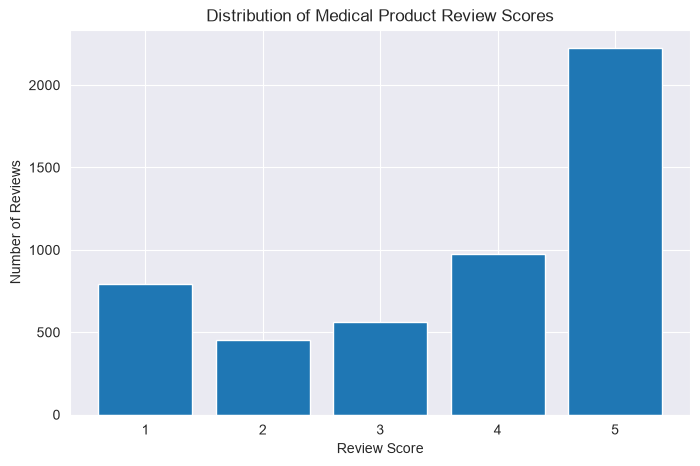

In [12]:
plt.figure(figsize=(8, 5))

# Count the number of reviews for each rating score
score_counts = data["Score"].value_counts().sort_index()
plt.bar(score_counts.index.astype(str), score_counts.values)

plt.title("Distribution of Medical Product Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

# Create Sentiment Categories

The rating score is converted into three sentiment categories:

- Scores 1 and 2 are classified as Negative.
- Score 3 is classified as Neutral.
- Scores 4 and 5 are classified as Positive.

For binary machine learning classification later in the notebook, neutral reviews will be excluded.

# Create Sentiment Categories

In [13]:
# Create a sentiment column

def create_sentiment(score):
    
    if score <= 2:
        return "Negative"
    
    elif score >= 4:
        return "Positive"
    
    else:
        return "Neutral"


data["Sentiment"] = data["Score"].apply(create_sentiment)

# Display the sentiment distribution
print(data["Sentiment"].value_counts())

Sentiment
Positive    3199
Negative    1241
Neutral      560
Name: count, dtype: int64


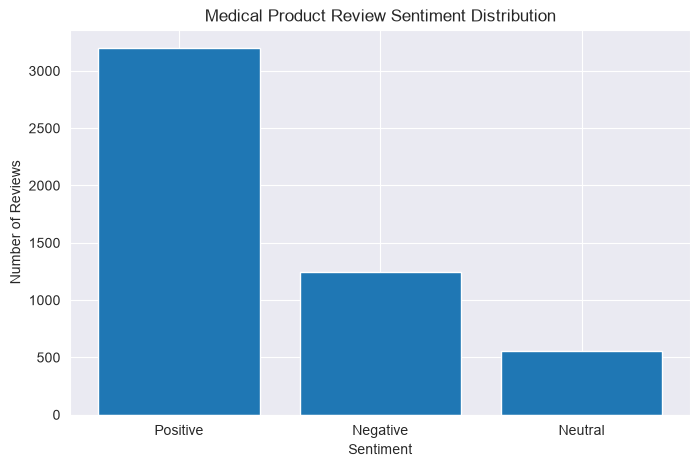

In [14]:
plt.figure(figsize=(8, 5))

# Count the number of reviews in each sentiment category
sentiment_counts = data["Sentiment"].value_counts()
plt.bar(sentiment_counts.index, sentiment_counts.values)

plt.title("Medical Product Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

# Keep only positive and negative reviews
# Neutral reviews (Score = 3) are excluded from this binary classification task.
sentiment_data = data[
    data["Sentiment"].isin(["Positive", "Negative"])
].copy()

# Reset the index
sentiment_data = sentiment_data.reset_index(drop=True)

print("Sentiment dataset shape:", sentiment_data.shape)

print("\nSentiment distribution:")
print(sentiment_data["Sentiment"].value_counts())

In [15]:
# Keep only positive and negative reviews
sentiment_data = data[
    data["Sentiment"].isin(["Positive", "Negative"])
].copy()

# Reset the index
sentiment_data = sentiment_data.reset_index(drop=True)

print("Sentiment dataset shape:", sentiment_data.shape)

print("\nSentiment distribution:")
print(sentiment_data["Sentiment"].value_counts())

Sentiment dataset shape: (4440, 4)

Sentiment distribution:
Sentiment
Positive    3199
Negative    1241
Name: count, dtype: int64


# Text Preprocessing

In [16]:
# Create a simple list of common English stopwords

stop_words = {
    "the", "a", "an", "and", "or", "but", "if", "is", "it",
    "this", "that", "to", "of", "in", "for", "on", "with",
    "as", "was", "were", "are", "be", "been", "by", "from",
    "at", "so", "very", "i", "me", "my", "we", "our", "you",
    "your", "they", "their", "he", "she", "his", "her",
    "have", "has", "had", "do", "does", "did"
}

In [17]:
# Function to clean the review text

def clean_text(text):
    
    # Convert text to lowercase
    text = text.lower()
    
    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)
    
    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    
    # Remove numbers
    text = re.sub(r"\d+", " ", text)
    
    # Split the text into words
    words = text.split()
    
    # Remove common stopwords
    words = [
        word for word in words
        if word not in stop_words
    ]
    
    # Join the words back together
    text = " ".join(words)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text

# Apply Text Cleaning

In [18]:
# Apply the cleaning function to the review text
sentiment_data["Clean_Text"] = sentiment_data["Text"].apply(clean_text)

# Display the original and cleaned reviews
sentiment_data[["Text", "Clean_Text"]].head()

,Text,Clean_Text
0,I go to the gym regularly and wanted a knee br...,go gym regularly wanted knee brace extra suppo...
1,"I like to hike at altitude, so I wanted a fing...",like hike altitude wanted fingertip pulse oxim...
2,My mother has a lung condition and her nurse s...,mother lung condition nurse suggested fingerti...
3,After starting a new medication I wanted to tr...,after starting new medication wanted track num...
4,"I tend to forget supplements, so I wanted some...",tend forget supplements wanted something small...


##### Interpretation

The preprocessing step converts the review text to lowercase, removes HTML tags, punctuation, numbers and selected common English stopwords.

This reduces some text noise and makes the reviews easier for the machine learning model to analyse. The original review text remains available in the dataset, while the cleaned text is used for analysis.

# Exploratory Data Analysis

In [19]:
# Calculate the number of words in each review
sentiment_data["Review_Length"] = sentiment_data["Clean_Text"].apply(
    lambda x: len(x.split())
)

# Display review length statistics
sentiment_data["Review_Length"].describe()

count    4440.00000
mean       72.68491
std        13.30594
min        38.00000
25%        63.00000
50%        72.00000
75%        82.00000
max       119.00000
Name: Review_Length, dtype: float64

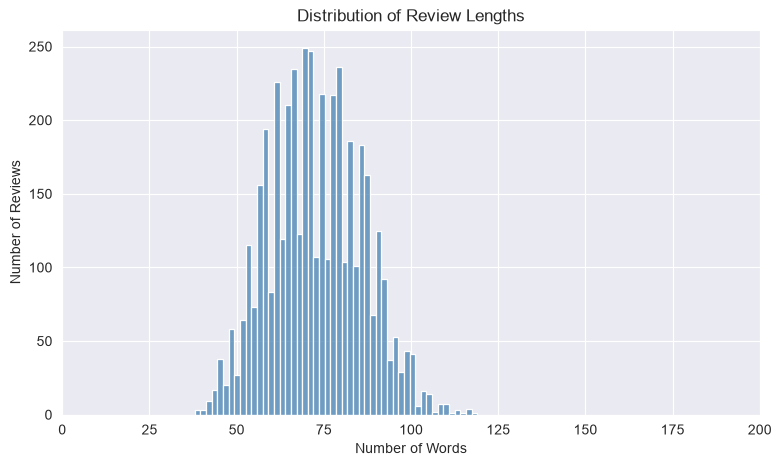

In [20]:
plt.figure(figsize=(9, 5))

sns.histplot(
    sentiment_data["Review_Length"],
    bins=50,
    color="steelblue"
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

# Limit the graph so extremely long reviews do not hide the main pattern
plt.xlim(0, 200)

plt.show()

Interpretation

The review length graph shows that reviewers write reviews of different lengths.

Most reviews are relatively short, while a smaller number of reviews contain many more words.

This is useful because longer reviews may contain more detailed information about the reviewer's experience.

In [21]:
from collections import Counter

# Combine all cleaned reviews
all_words = " ".join(
    sentiment_data["Clean_Text"]
)

# Count the words
word_counts = Counter(
    all_words.split()
)

# Get the 20 most common words
most_common_words = word_counts.most_common(20)

# Display the results
most_common_words

[('not', 5637),
 ('after', 4430),
 ('which', 3863),
 ('am', 3244),
 ('few', 3025),
 ('up', 2968),
 ('about', 2964),
 ('can', 2559),
 ('when', 2460),
 ('one', 2457),
 ('what', 2339),
 ('without', 2285),
 ('thing', 2062),
 ('than', 2061),
 ('like', 1924),
 ('would', 1892),
 ('easy', 1875),
 ('top', 1809),
 ('even', 1766),
 ('small', 1757)]

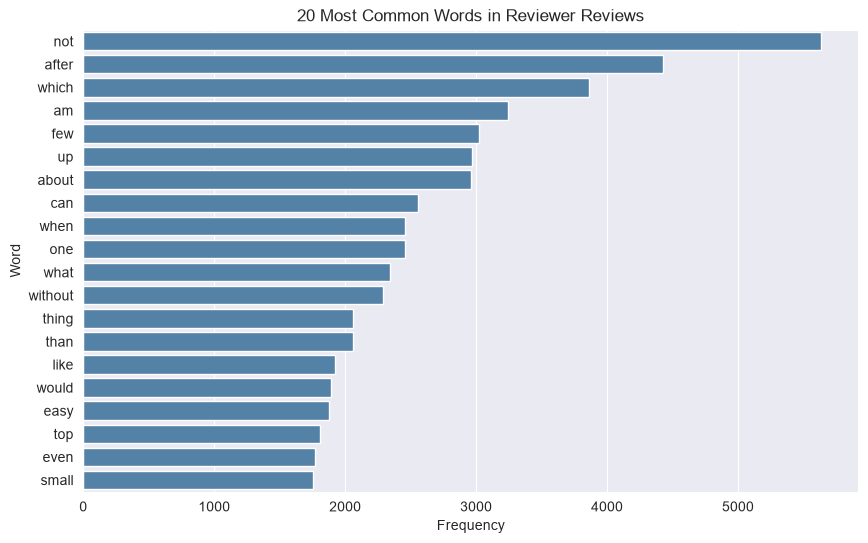

In [22]:
# Convert the results into a DataFrame
common_words_df = pd.DataFrame(
    most_common_words,
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=common_words_df,
    x="Frequency",
    y="Word",
    color="steelblue"
)

plt.title("20 Most Common Words in Reviewer Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

The most common words provide an initial indication of what reviewers discuss in their medical product reviews.

However, word frequency alone cannot tell us whether reviewers are satisfied or dissatisfied with a product. Sentiment analysis and topic modelling are therefore also used to explore the review text.

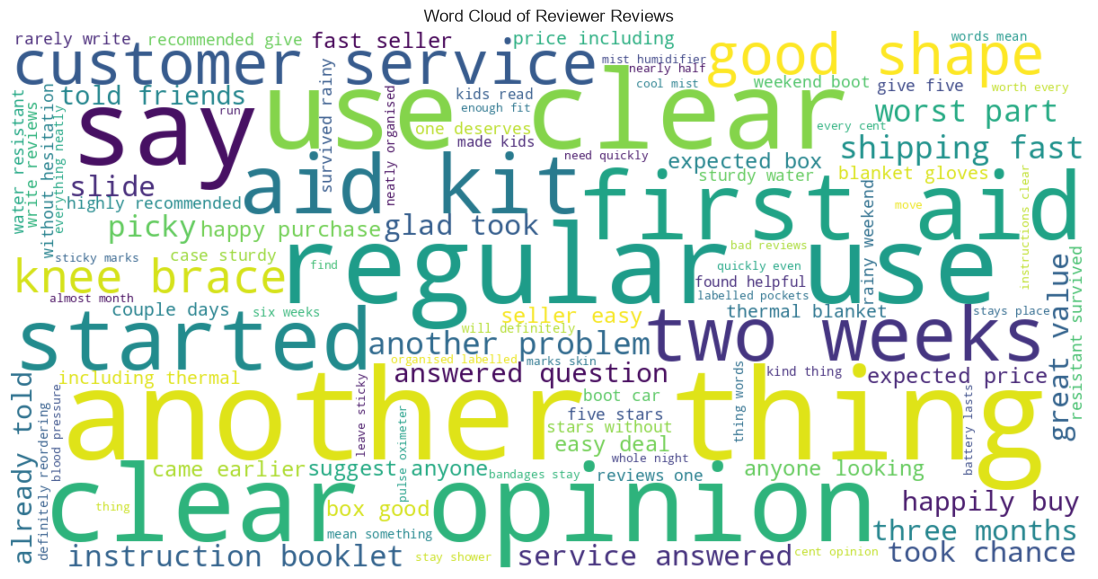

In [23]:
# Create a word cloud using the most common words

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(all_words)

plt.figure(figsize=(15, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Word Cloud of Reviewer Reviews")

plt.show()

In [24]:
# Combine positive reviews
positive_text = " ".join(
    sentiment_data[
        sentiment_data["Sentiment"] == "Positive"
    ]["Clean_Text"]
)

# Combine negative reviews
negative_text = " ".join(
    sentiment_data[
        sentiment_data["Sentiment"] == "Negative"
    ]["Clean_Text"]
)

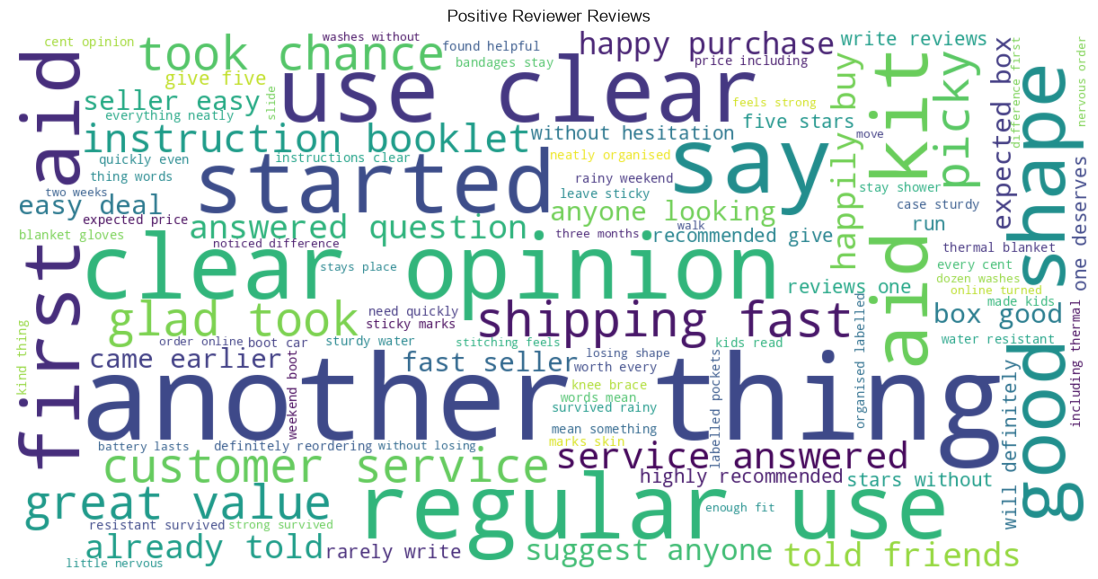

In [25]:
positive_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(positive_text)

plt.figure(figsize=(15, 7))

plt.imshow(
    positive_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Positive Reviewer Reviews")

plt.show()

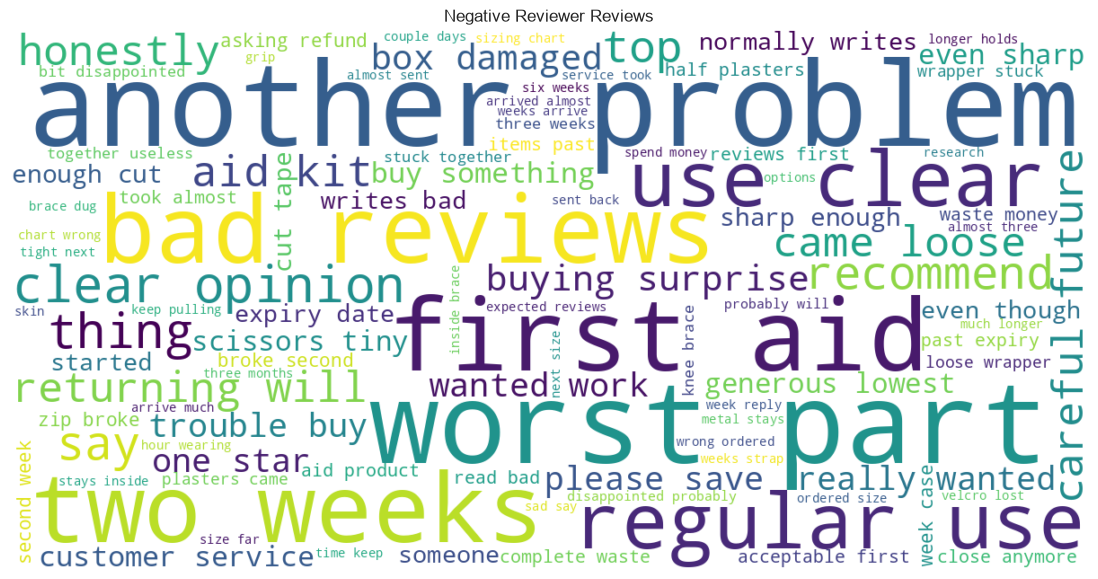

In [26]:
negative_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(negative_text)

plt.figure(figsize=(15, 7))

plt.imshow(
    negative_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Negative Reviewer Reviews")

plt.show()

The two word clouds allow us to compare the language used in positive and negative medical product reviews.

Words that appear frequently in positive reviews may indicate product features reviewers appreciate. Words frequently appearing in negative reviews may point to reported problems or areas where the product experience could be improved. These are themes in user feedback, not verified clinical findings.

In [27]:
# Take a sample of the dataset for model training

sample_size = min(50000, len(sentiment_data))

model_data = sentiment_data.sample(
    n=sample_size,
    random_state=42
)

# Reset index
model_data = model_data.reset_index(drop=True)

print("Model dataset shape:", model_data.shape)

Model dataset shape: (4440, 6)


In [28]:
# Define the text features
X = model_data["Clean_Text"]

# Define the target
y = model_data["Sentiment"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3552
Testing records: 888


# Feature Engineering

In [29]:
# Create a TF-IDF vectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Fit the vectorizer on the training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform the test data
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (3552, 6922)
Testing TF-IDF shape: (888, 6922)


##### Interpretation

TF-IDF (Term Frequency–Inverse Document Frequency) converts review text into numerical features that a machine learning model can process.

The vectorizer uses individual words and two-word combinations. This allows phrases such as "very good" or "not good" to contribute information when the model distinguishes positive from negative review sentiment.

# Create a Machine Learning Pipelines

In [30]:
# Create a pipeline containing:
# 1. TF-IDF
# 2. Logistic Regression

sentiment_pipeline = Pipeline([
    
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )
    ),
    
    (
        "logistic",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

In [31]:
# Train the sentiment classification pipeline

sentiment_pipeline.fit(
    X_train,
    y_train
)

print("Model trained successfully.")

Model trained successfully.


In [32]:
# Make predictions on the test data

y_pred = sentiment_pipeline.predict(
    X_test
)

# Display some actual and predicted results

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,Positive,Positive
1,Positive,Positive
2,Positive,Positive
3,Positive,Positive
4,Positive,Positive
5,Positive,Positive
6,Positive,Positive
7,Positive,Positive
8,Negative,Negative
9,Positive,Positive


In [33]:
# Calculate accuracy
accuracy = accuracy_score(
    y_test,
    y_pred
)

# Calculate precision
precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

# Calculate recall
recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

# Calculate F1-score
f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("SENTIMENT MODEL RESULTS")
print("-----------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

SENTIMENT MODEL RESULTS
-----------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


##### Interpretation

The model is evaluated using accuracy, precision, recall and F1-score.

- Accuracy measures the overall proportion of correct predictions.
- Precision measures how often predictions for a class are correct.
- Recall measures how many of the actual reviews in a class are correctly identified.
- F1-score combines precision and recall into one measure.

A higher score generally indicates stronger classification performance. The weighted averages account for the different number of positive and negative reviews.

In [34]:
# Display detailed classification results

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       248
    Positive       1.00      1.00      1.00       640

    accuracy                           1.00       888
   macro avg       1.00      1.00      1.00       888
weighted avg       1.00      1.00      1.00       888



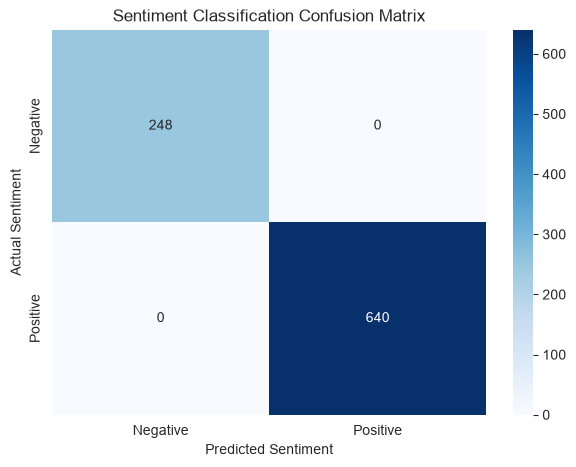

In [35]:
# Create the confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

# Plot the confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Sentiment Classification Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

##### Interpretation

The confusion matrix shows the number of correctly and incorrectly classified reviews.

The diagonal values represent correct predictions. Values outside the diagonal represent incorrect predictions.

This helps assess how well the model identifies positive and negative medical product reviews. In a real-world setting, incorrectly classifying a negative review as positive could cause an organisation to overlook an important user concern.

In [36]:
# Create an improved pipeline

improved_pipeline = Pipeline([
    
    (
        "tfidf",
        TfidfVectorizer()
    ),
    
    (
        "logistic",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

In [37]:
# Define different parameters to test

parameters = {
    "tfidf__max_features": [5000, 10000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "logistic__C": [0.1, 1, 10]
}

# Use GridSearchCV to test different combinations

grid_search = GridSearchCV(
    improved_pipeline,
    parameters,
    cv=3,
    scoring="f1_weighted",
    n_jobs=-1
)

# Train the different model combinations

grid_search.fit(
    X_train,
    y_train
)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(grid_search.best_score_)

Best parameters:
{'logistic__C': 1, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 2)}

Best cross-validation F1-score:
1.0


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best parameters:
{'logistic__C': 1, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 2)}

Best cross-validation F1-score:
1.0


In [38]:
# Get the best model from GridSearchCV

best_model = grid_search.best_estimator_

# Make predictions using the improved model

improved_pred = best_model.predict(
    X_test
)

# Calculate improved metrics

improved_accuracy = accuracy_score(
    y_test,
    improved_pred
)

improved_precision = precision_score(
    y_test,
    improved_pred,
    average="weighted"
)

improved_recall = recall_score(
    y_test,
    improved_pred,
    average="weighted"
)

improved_f1 = f1_score(
    y_test,
    improved_pred,
    average="weighted"
)

print("IMPROVED MODEL RESULTS")
print("----------------------")
print("Accuracy :", improved_accuracy)
print("Precision:", improved_precision)
print("Recall   :", improved_recall)
print("F1 Score :", improved_f1)

IMPROVED MODEL RESULTS
----------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


# Compare the Models

In [39]:
# Create a table comparing the baseline and improved models

model_comparison = pd.DataFrame({
    
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    
    "Baseline Model": [
        accuracy,
        precision,
        recall,
        f1
    ],
    
    "Improved Model": [
        improved_accuracy,
        improved_precision,
        improved_recall,
        improved_f1
    ]
})

model_comparison

,Metric,Baseline Model,Improved Model
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1 Score,1.0,1.0


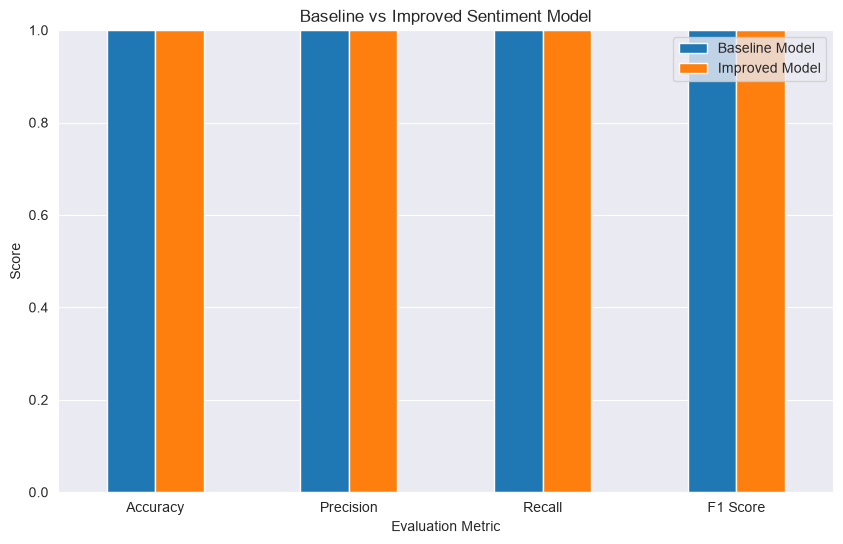

In [40]:
# Visualise the model comparison

comparison_plot = model_comparison.set_index(
    "Metric"
)

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Baseline vs Improved Sentiment Model")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.show()

##### Interpretation

The baseline and improved models are compared using the same evaluation metrics and test dataset.

The improvement is assessed by looking at changes in accuracy, precision, recall and F1-score. F1-score is particularly useful because it considers both precision and recall, which is important when the classes are not equally represented.

##### Important note about the model results

If the evaluation metrics are extremely high (including 100%), this should be interpreted cautiously. This dataset contains a limited set of 5,000 reviews, and repeated writing patterns or wording that closely follows the rating labels can make classification unusually easy.

A high test score on this dataset does not guarantee that the model will perform equally well on new reviews from real medical product platforms. Further validation using a larger, independently collected dataset would be needed before using the model in practice.

In [41]:
# Create TF-IDF features for topic modelling

topic_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

topic_features = topic_vectorizer.fit_transform(
    model_data["Clean_Text"]
)

print("Topic modelling data shape:", topic_features.shape)

Topic modelling data shape: (4440, 1002)


In [42]:
# Create an LDA model with five topics

lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method="batch"
)

# Train the LDA model

lda_model.fit(
    topic_features
)

print("LDA model trained successfully.")

LDA model trained successfully.


In [43]:
# Get the words used by the topic model

feature_names = topic_vectorizer.get_feature_names_out()

# Display the top 10 words for each topic

for topic_number, topic in enumerate(
    lda_model.components_
):
    
    top_words = [
        feature_names[i]
        for i in topic.argsort()[-10:][::-1]
    ]
    
    print(
        f"Topic {topic_number + 1}:",
        ", ".join(top_words)
    )

Topic 1: night, numbers, readings, reading, mist, pulse, seconds, easy, thing, lasts
Topic 2: ear, blocked, ears, box, earplugs, felt, sleeping, pack, block, noise
Topic 3: aid, kit, case, car, expected, instruction, plasters, booklet, thermal, blanket
Topic 4: meter, father, mother, rubber, instructions, strips, hurt, cane, folding, walking
Topic 5: brace, day, tablets, stays, easy, size, knee, washes, fit, shape


In [44]:
# Calculate the topic probabilities for every review

topic_distribution = lda_model.transform(
    topic_features
)

# Find the topic with the highest probability
dominant_topic = topic_distribution.argmax(
    axis=1
) + 1

# Add the dominant topic to the dataset

model_data["Dominant_Topic"] = dominant_topic

# Count the number of reviews assigned to each topic

topic_counts = (
    model_data["Dominant_Topic"]
    .value_counts()
    .sort_index()
)

print(topic_counts)

Dominant_Topic
1    1200
2     576
3     855
4     473
5    1336
Name: count, dtype: int64


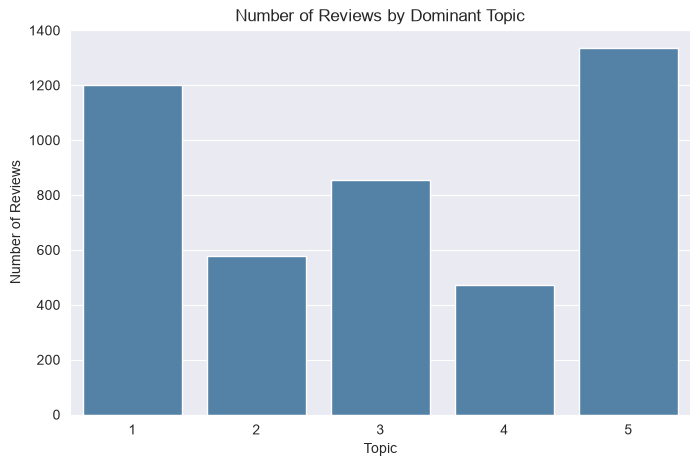

In [45]:
# Plot the number of reviews for each topic

plt.figure(figsize=(8, 5))

sns.barplot(
    x=topic_counts.index,
    y=topic_counts.values,
    color="steelblue"
)

plt.title("Number of Reviews by Dominant Topic")
plt.xlabel("Topic")
plt.ylabel("Number of Reviews")

plt.show()

In [46]:
# Add sentiment information to the model data

model_data["Sentiment"] = model_data["Sentiment"].values

# Compare topics and sentiment

topic_sentiment = pd.crosstab(
    model_data["Dominant_Topic"],
    model_data["Sentiment"],
    normalize="index"
) * 100

topic_sentiment

Sentiment,Negative,Positive
Dominant_Topic,,
1,22.166667,77.833333
2,29.166667,70.833333
3,29.005848,70.994152
4,41.649049,58.350951
5,27.095808,72.904192


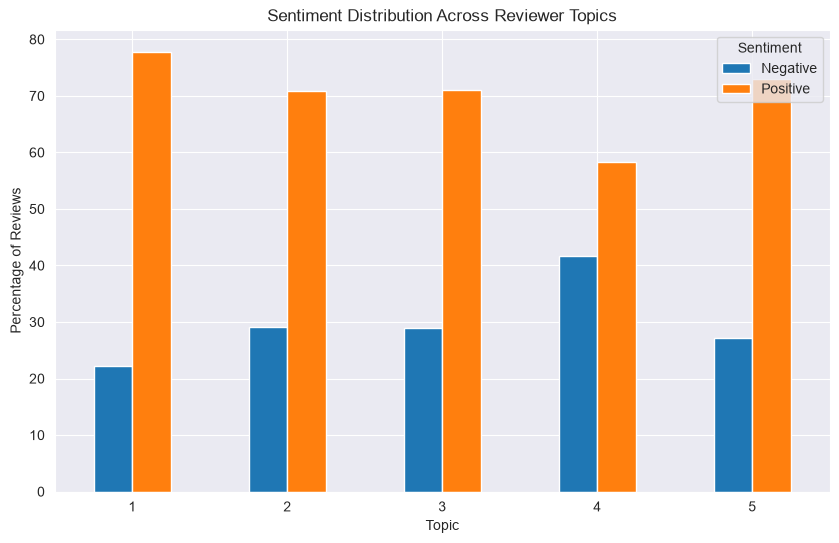

In [47]:
# Plot sentiment distribution for each topic

topic_sentiment.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Distribution Across Reviewer Topics")
plt.xlabel("Topic")
plt.ylabel("Percentage of Reviews")

plt.xticks(rotation=0)

plt.legend(
    title="Sentiment"
)

plt.show()

##### Interpretation

This analysis combines topic modelling and sentiment analysis.

It shows the main themes discussed in medical product reviews and whether the reviews assigned to each theme are positive or negative.

The results can help product teams identify recurring areas of satisfaction and dissatisfaction. The topics are automatically generated from text and should be interpreted by reviewing the actual comments associated with each topic.

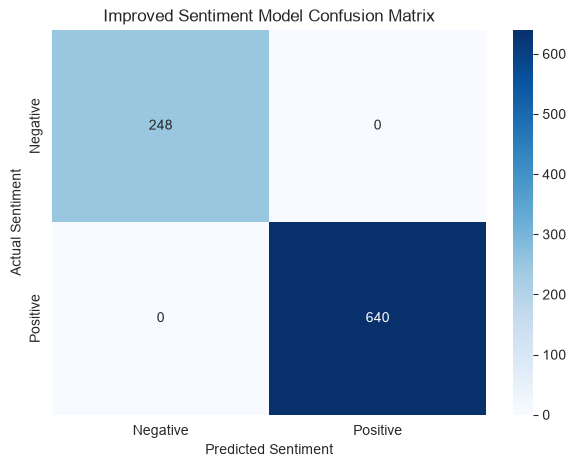

In [48]:
# Create a confusion matrix for the improved model

final_cm = confusion_matrix(
    y_test,
    improved_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Improved Sentiment Model Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [49]:
# Create a final summary table

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    
    "Baseline": [
        accuracy,
        precision,
        recall,
        f1
    ],
    
    "Improved": [
        improved_accuracy,
        improved_precision,
        improved_recall,
        improved_f1
    ]
})

final_results

,Metric,Baseline,Improved
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1 Score,1.0,1.0


# CONCLUSION

This project analysed a dataset of 5,000 medical product reviews using text data analysis and machine learning techniques.

The dataset contains review information such as product identifiers, reviewer details, helpfulness counts, rating scores, timestamps, review summaries and full review text. For the sentiment analysis, the Score, Summary and Text columns were selected. The data was checked for missing values and duplicate records before the review text was prepared for analysis.

Exploratory data analysis was performed using review score distributions, review lengths, word frequencies and word clouds. Reviews with scores of 1 or 2 were labelled Negative, reviews with scores of 4 or 5 were labelled Positive, and reviews with a score of 3 were labelled Neutral. Neutral reviews were excluded from the binary sentiment classification task.

TF-IDF was used to convert the cleaned review text into numerical features. A Logistic Regression model was trained to classify reviews as positive or negative. The model was evaluated using accuracy, precision, recall and F1-score. GridSearchCV was then used to test different parameter combinations and identify an improved model.

Latent Dirichlet Allocation (LDA) topic modelling was also used to identify recurring themes in the review text. Comparing the topics with sentiment helps show which themes are more commonly associated with positive or negative reviews.

Overall, combining sentiment analysis with topic modelling provides a structured way to explore reviewer opinions, identify recurring product-related concerns and highlight features that reviewers appreciate. These findings can support the analysis of user feedback and product experience.

**Important limitation:** The dataset contains user-generated reviews of medical products. Ratings and review text represent individual opinions and reported experiences; they do not establish medical accuracy, safety, effectiveness or suitability. Clinical decisions should not be made from this sentiment analysis.